# Project 1 — Wholesale Customer Segmentation
**Name:** ATUHAIRE PAULINE 
**REG Number:** S25M19/016
**Access Number:** B35093
**Course:** DSC8307 Data Mining, Modeling and Analytics  
**Dataset:** 440 wholesale customers; annual spending across six product categories.

## 1. Problem formulation
The objective is to identify groups of customers with similar spending profiles and translate those profiles into differentiated service strategies. The six spending variables are the segmentation features. `Channel` and `Region` are retained for post-clustering interpretation rather than used to define the segments: this keeps the segments grounded in purchasing behaviour and allows us to test whether they align with existing business classifications.

The source README defines Channel as Horeca/Retail and Region as Lisbon/Oporto/Other. The CSV encodes these as integers (1/2 and 1/2/3 respectively).

In [29]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram
from pathlib import Path
RANDOM_STATE = 42
DATA = Path("data/wholesale-customers.csv")
if not DATA.exists():
    DATA = Path("../data/wholesale-customers.csv")
df = pd.read_csv(DATA)
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 2. Data understanding and preparation
The data contains 440 rows and eight columns: six continuous annual-spend variables plus two categorical descriptors. Check missingness, duplicates, ranges and skew. Spending is non-negative and highly right-skewed, so `log1p` reduces the influence of extreme spenders while preserving zeros. Standardisation is then necessary because clustering is distance-based and the spending variables have different scales. No customer rows are removed solely for having high spending: those may be commercially important customers.

Shape: (440, 8)

Missing values:
 Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicatessen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


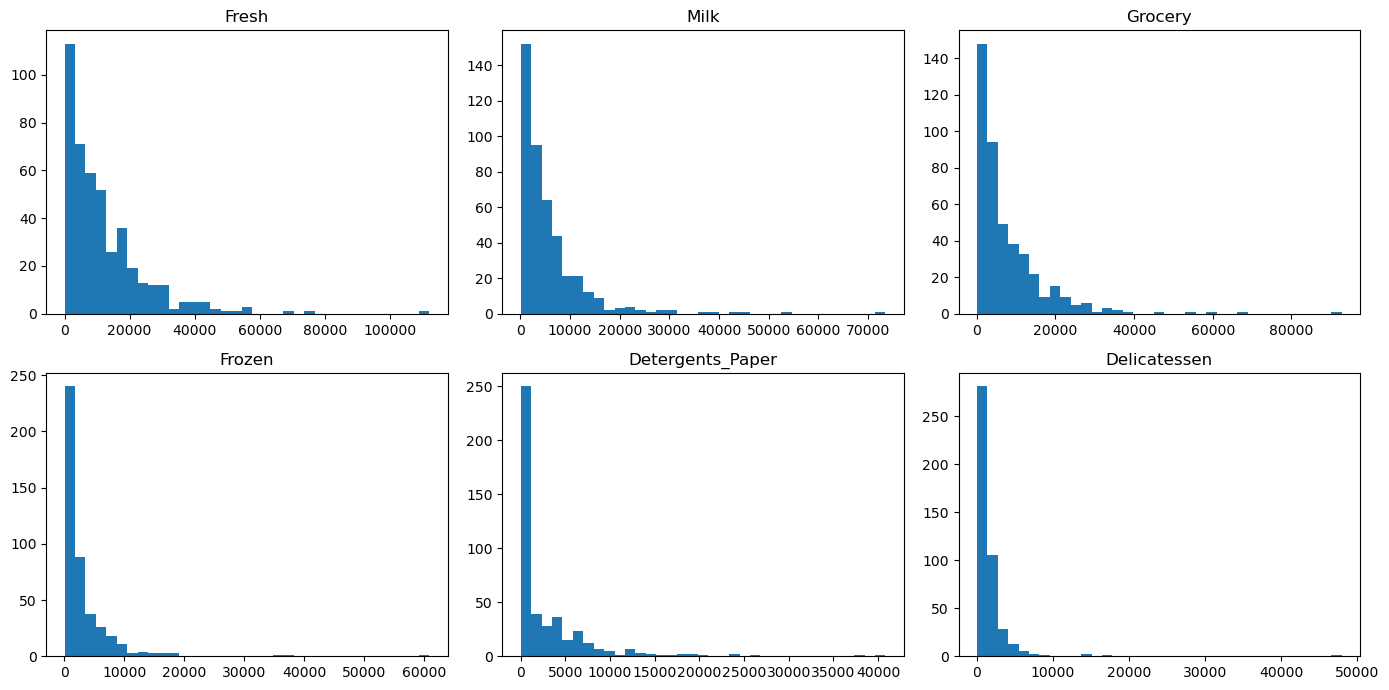

In [30]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
spend_cols = ["Fresh","Milk","Grocery","Frozen","Detergents_Paper","Delicatessen"]
display(df[spend_cols].describe().T)
fig, axes = plt.subplots(2,3,figsize=(14,7))
for c, ax in zip(spend_cols, axes.ravel()):
    ax.hist(df[c], bins=35)
    ax.set_title(c)
plt.tight_layout()

In [31]:
X_raw = df[spend_cols].copy()
X_log = np.log1p(X_raw)
scaler = StandardScaler()
X = scaler.fit_transform(X_log)
print("Prepared matrix:", X.shape, "| finite:", np.isfinite(X).all())

Prepared matrix: (440, 6) | finite: True


## 3. Cluster tendency
The Hopkins statistic compares nearest-neighbour distances for sampled real observations with distances for artificial uniform points. Values around 0.5 indicate weak tendency to cluster; values substantially above 0.5 suggest spatial structure. It is a diagnostic, not proof that a particular clustering solution is valid. The feature space is transformed and standardised before calculation.

In [32]:
def hopkins_statistic(X, sample_size=80, random_state=42):
    rng = np.random.default_rng(random_state)
    n, d = X.shape
    m = min(sample_size, max(10, n//10))
    idx = rng.choice(n, m, replace=False)
    real = X[idx]
    mins, maxs = X.min(axis=0), X.max(axis=0)
    synthetic = rng.uniform(mins, maxs, size=(m,d))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    # distance from real point to its nearest other real point
    u = nn.kneighbors(real, n_neighbors=2)[0][:,1]
    # distance from artificial point to nearest real point
    w = nn.kneighbors(synthetic, n_neighbors=1)[0][:,0]
    return float(np.sum(w)/(np.sum(u)+np.sum(w)))
H = hopkins_statistic(X)
print(f"Hopkins statistic: {H:.3f}")

Hopkins statistic: 0.806


## 4. Partitioning: K-means
K-means is an efficient, interpretable partitioning baseline. It assigns every customer to one of *k* clusters and represents each cluster by a centroid. Its limitations are sensitivity to scaling, initialisation and outliers, and a preference for roughly spherical clusters. We compare several values of *k* using silhouette (higher is better), Davies–Bouldin (lower is better) and Calinski–Harabasz (higher is better), then select a solution using both diagnostics and business interpretability.

In [33]:
rows=[]
models={}
for k in range(2,8):
    km=KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels=km.fit_predict(X)
    models[k]=km
    rows.append({"k":k,"silhouette":silhouette_score(X,labels),
                 "davies_bouldin":davies_bouldin_score(X,labels),
                 "calinski_harabasz":calinski_harabasz_score(X,labels),
                 "inertia":km.inertia_})
kmeans_scores=pd.DataFrame(rows)
display(kmeans_scores.round(3))
best_k=int(kmeans_scores.sort_values("silhouette",ascending=False).iloc[0]["k"])
print("Highest silhouette k:",best_k)

,k,silhouette,davies_bouldin,calinski_harabasz,inertia
0,2,0.290,1.352,189.050,1844.064
1,3,0.258,1.348,152.837,1553.413
2,4,0.188,1.541,131.320,1386.863
3,5,0.192,1.484,118.000,1266.149
4,6,0.195,1.414,108.300,1174.536
5,7,0.196,1.392,103.208,1086.359


Highest silhouette k: 2


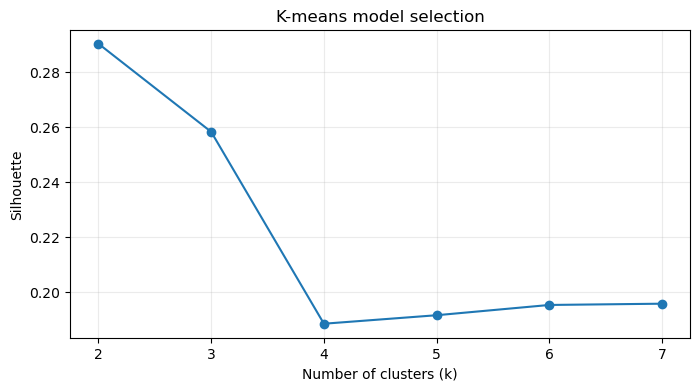

In [34]:
plt.figure(figsize=(8,4))
plt.plot(kmeans_scores.k,kmeans_scores.silhouette,marker="o")
plt.xlabel("Number of clusters (k)"); plt.ylabel("Silhouette"); plt.title("K-means model selection")
plt.xticks(kmeans_scores.k); plt.grid(alpha=.25); plt.show()

## 5. Hierarchical clustering
Agglomerative clustering with Ward linkage merges the closest groups while minimising within-cluster variance. It provides a hierarchy that can be inspected with a dendrogram and does not require iterative centroid updates. It can be computationally more expensive and, like K-means, is sensitive to distance and scaling. We compare its silhouette and cluster sizes at the selected *k*.

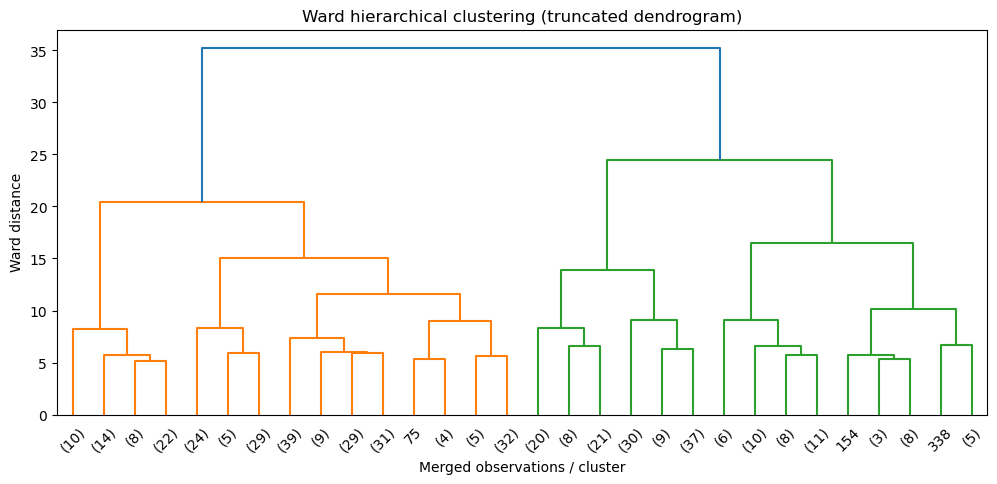

Agglomerative silhouette: 0.258
Cluster sizes: {0: 178, 1: 262}


In [35]:
Z=linkage(X,method="ward")
plt.figure(figsize=(12,5))
dendrogram(Z,truncate_mode="lastp",p=30,show_leaf_counts=True)
plt.title("Ward hierarchical clustering (truncated dendrogram)")
plt.xlabel("Merged observations / cluster"); plt.ylabel("Ward distance"); plt.show()
agg=AgglomerativeClustering(n_clusters=best_k,linkage="ward")
agg_labels=agg.fit_predict(X)
print("Agglomerative silhouette:",round(silhouette_score(X,agg_labels),3))
print("Cluster sizes:",pd.Series(agg_labels).value_counts().sort_index().to_dict())

## 6. Density-based clustering: DBSCAN
DBSCAN groups dense neighbourhoods and labels observations outside those neighbourhoods as noise (`-1`). It can discover irregular shapes and does not require a preselected cluster count. However, it is sensitive to `eps` and `min_samples`; standard DBSCAN can classify many points as noise when customer density varies. The k-distance plot helps select a plausible `eps`. We report the number of clusters, noise share and silhouette on non-noise observations (only when at least two clusters remain). This silhouette is not directly comparable with scores computed on all observations because noise is excluded.

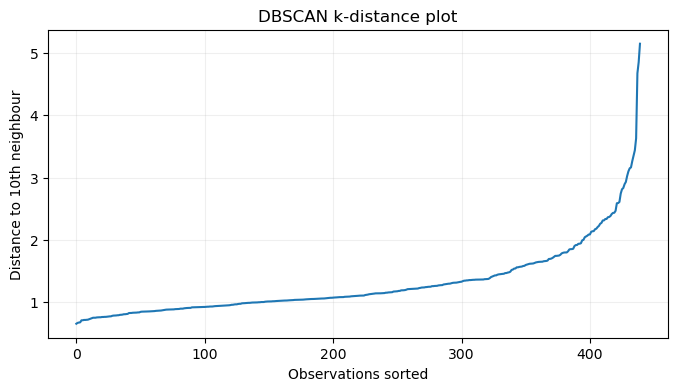

In [36]:
min_samples=10
nn=NearestNeighbors(n_neighbors=min_samples).fit(X)
distances,_=nn.kneighbors(X)
kdist=np.sort(distances[:,-1])
plt.figure(figsize=(8,4)); plt.plot(kdist); plt.title("DBSCAN k-distance plot")
plt.xlabel("Observations sorted"); plt.ylabel(f"Distance to {min_samples}th neighbour"); plt.grid(alpha=.2); plt.show()

In [37]:
# A transparent starting value; inspect the k-distance elbow and adjust if the plot indicates otherwise.
eps=float(np.quantile(kdist,0.90))
db=DBSCAN(eps=eps,min_samples=min_samples)
db_labels=db.fit_predict(X)
n_clusters=len(set(db_labels)-{-1})
noise_share=float(np.mean(db_labels==-1))
non_noise=db_labels!=-1
db_sil=(silhouette_score(X[non_noise],db_labels[non_noise])
        if n_clusters>=2 and non_noise.sum()>n_clusters else np.nan)
print({"eps":round(eps,3),"clusters":n_clusters,"noise_share":round(noise_share,3),
       "non_noise_silhouette":None if np.isnan(db_sil) else round(db_sil,3)})

{'eps': 2.005, 'clusters': 1, 'noise_share': 0.036, 'non_noise_silhouette': None}


## 7. Compare methods and choose a segmentation
Silhouette, Davies–Bouldin and Calinski–Harabasz quantify separation/compactness, but none alone determines business usefulness. Partitioning and Ward clustering assign all customers; DBSCAN can leave noise unassigned. Interpretability also depends on whether cluster profiles are distinct and actionable. The final segmentation below uses the K-means solution with the strongest silhouette in the tested range; review the score table and profiles before adopting it operationally.

In [38]:
comparison=pd.DataFrame([
 {"method":"K-means","clusters":best_k,"assigned":len(df),"noise_share":0,
  "silhouette":float(kmeans_scores.loc[kmeans_scores.k==best_k,"silhouette"].iloc[0])},
 {"method":"Agglomerative Ward","clusters":len(np.unique(agg_labels)),"assigned":len(df),"noise_share":0,
  "silhouette":silhouette_score(X,agg_labels)},
 {"method":"DBSCAN","clusters":n_clusters,"assigned":int(non_noise.sum()),"noise_share":noise_share,
  "silhouette":db_sil}
])
display(comparison.round(3))
final_model=models[best_k]
df["Segment"]=final_model.labels_
print(df["Segment"].value_counts().sort_index())

,method,clusters,assigned,noise_share,silhouette
0,K-means,2,440,0.000,0.290
1,Agglomerative Ward,2,440,0.000,0.258
2,DBSCAN,1,424,0.036,NaN


Segment
0    252
1    188
Name: count, dtype: int64


## 8. Segment profiles and descriptive names
Profiles are shown as median annual spend in original monetary units, with segment sizes. Medians are robust to the extreme values present in spending data. Segment names should be assigned from the observed profile table, not from cluster number (cluster labels are arbitrary). The following cell creates a profile table and a relative-spend heatmap to support that naming.

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,Customers
Segment,,,,,,,
0,10348.0,1871.0,2406.0,2225.0,328.0,750.0,252
1,5406.0,7690.0,11527.0,1062.0,4495.0,1388.0,188


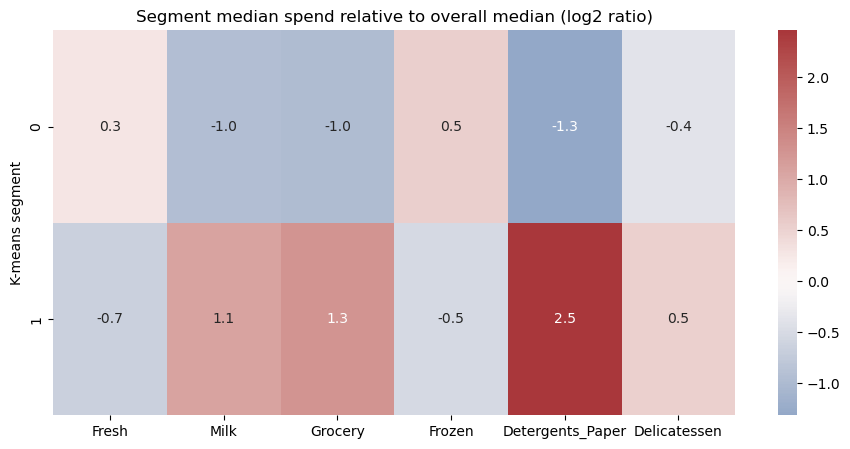

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Segment_Name,,,,,,
Fresh-led customers,10348.0,1871.0,2406.0,2225.0,328.0,750.0
"Grocery, milk and household-led customers",5406.0,7690.0,11527.0,1062.0,4495.0,1388.0


\nChannel distribution by segment (row proportions):


Channel,1,2
Segment_Name,,
Fresh-led customers,0.97,0.03
"Grocery, milk and household-led customers",0.29,0.71


\nRegion distribution by segment (row proportions):


Region,1,2,3
Segment_Name,,,
Fresh-led customers,0.19,0.11,0.70
"Grocery, milk and household-led customers",0.15,0.10,0.74


In [39]:
profile=df.groupby("Segment")[spend_cols].median().round(0)
profile["Customers"]=df.groupby("Segment").size()
display(profile)
relative=profile[spend_cols].div(df[spend_cols].median())
plt.figure(figsize=(11,5))
sns.heatmap(np.log2(relative),annot=True,fmt=".1f",cmap="vlag",center=0)
plt.title("Segment median spend relative to overall median (log2 ratio)")
plt.ylabel("K-means segment"); plt.show()
# Descriptive labels are based on the observed median-spend profiles above.
segment_names = {
    0: "Fresh-led customers",
    1: "Grocery, milk and household-led customers"
}
df["Segment_Name"] = df["Segment"].map(segment_names).fillna(df["Segment"].astype(str))
display(df.groupby("Segment_Name")[spend_cols].median().round(0))
print("\\nChannel distribution by segment (row proportions):")
display(pd.crosstab(df["Segment_Name"],df["Channel"],normalize="index").round(2))
print("\\nRegion distribution by segment (row proportions):")
display(pd.crosstab(df["Segment_Name"],df["Region"],normalize="index").round(2))


## 9. Business recommendations and limitations
Use the profile table to attach names such as *Fresh-led bulk buyers*, *Retail-oriented grocery and household buyers*, or *Lower-volume diversified buyers* only where the median pattern supports the label. Suggested service actions:
- **Fresh-led / bulk buyers:** reliable fresh-product availability, frequent replenishment, cold-chain coordination and volume-based account planning.
- **Grocery, milk and detergents-led buyers:** bundled promotions, category cross-selling, shelf/display support and predictable delivery schedules.
- **Broad, high-spend buyers:** named account management, tailored contracts, priority fulfilment and demand forecasting.
- **Lower-volume or specialised buyers:** flexible order sizes, targeted assortments and lower-cost delivery options.

These are conditional recommendations: map each actual segment to the closest supported profile in the table. Validate stability across random seeds and samples before deployment. Spending is historical annual spend, not profit, margin, order frequency or customer potential; do not infer these unobserved quantities. The sample contains only 440 customers and may not represent all future customers.